In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# 1. Load dataset
df = pd.read_csv("california_housing.csv")

X = df["AveRooms"].values
y = df["MedHouseVal"].values

In [3]:
# 2. Normalize input
X = (X - np.min(X)) / (np.max(X) - np.min(X))

In [4]:
# 3. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
# 4. Initialize parameters
theta0 = 0
theta1 = 0

n = len(X_train)
cost_history = []

learning_rate = 0.01
iterations = 1000

In [6]:
# 5. Gradient Descent
for i in range(iterations):

    # Prediction
    y_pred = theta0 + theta1 * X_train

    # Error
    error = y_train - y_pred

    # Gradients
    d_theta0 = (-2/n) * np.sum(error)
    d_theta1 = (-2/n) * np.sum(error * X_train)

    # Update parameters
    theta0 = theta0 - learning_rate * d_theta0
    theta1 = theta1 - learning_rate * d_theta1

    # Cost
    cost = (1/n) * np.sum(error**2)
    cost_history.append(cost)

In [7]:
# 6. Testing
y_test_pred = theta0 + theta1 * X_test

# 7. Evaluation
print("Gradient Descent")
print("Intercept:", theta0)
print("Slope:", theta1)

print("MSE:", mean_squared_error(y_test, y_test_pred))
print("R2:", r2_score(y_test, y_test_pred))

Gradient Descent
Intercept: 2.0678579963647024
Slope: 0.12875094730926337
MSE: 1.3099404724965105
R2: 0.00035752635411423483


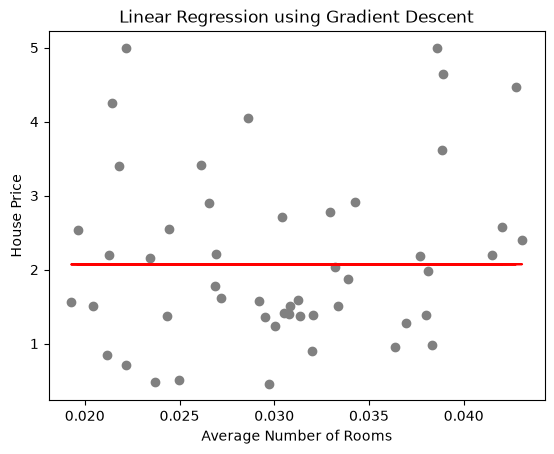

In [8]:
# 8. Plot regression line
plt.scatter(X_test[:50], y_test[:50], color="gray")
plt.plot(X_test[:50], y_test_pred[:50], color="red")
plt.xlabel("Average Number of Rooms")
plt.ylabel("House Price")
plt.title("Linear Regression using Gradient Descent")
plt.show()

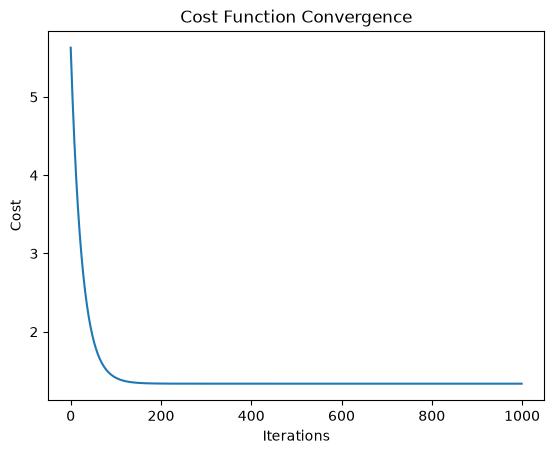

In [9]:
# 9. Cost convergence
plt.plot(range(iterations), cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Function Convergence")
plt.show()